# Notebook 3 — Investigating the 2011 Tohoku Earthquake

In this optional extension activity, you will analyse a hydroacoustic recording associated with the 2011 Tohoku earthquake.

You will use the same basic tools introduced earlier in the course:

- waveform;
- FFT;
- spectrogram;
- simple filtering.

The aim is to identify the main characteristics of the earthquake signal and distinguish it from the background acoustic environment.

In [1]:
# Import the libraries used in this notebook

import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import spectrogram, butter, sosfiltfilt


# Load the hydroacoustic signal

file_path = "mag_91_2011_03_11.txt"

# The file contains a NumPy array despite the .txt extension
signal = np.load(file_path, allow_pickle=False)

# Sampling frequency
fs = 250  # Hz

# Centre the signal around zero
signal = signal - np.mean(signal)

# Create the time vector
time = np.arange(len(signal)) / fs

# Basic information
duration = len(signal) / fs
nyquist = fs / 2

print("Loaded:", file_path)
print("Number of samples:", len(signal))
print("Sampling frequency:", fs, "Hz")
print(f"Duration: {duration:.1f} seconds")
print(f"Duration: {duration/60:.1f} minutes")
print("Nyquist frequency:", nyquist, "Hz")

Loaded: mag_91_2011_03_11.txt
Number of samples: 225000
Sampling frequency: 250 Hz
Duration: 900.0 seconds
Duration: 15.0 minutes
Nyquist frequency: 125.0 Hz


## 1. Examine the waveform

The waveform shows how the recorded acoustic pressure changes through time.

Look for changes in amplitude and for sections where the signal becomes clearly different from the background.

Questions:

1. Can you identify the main earthquake signal?
2. Does the event appear suddenly or gradually?
3. Is the event short or does it last for a substantial period?
4. How does the earthquake signal differ from the quieter parts of the recording?

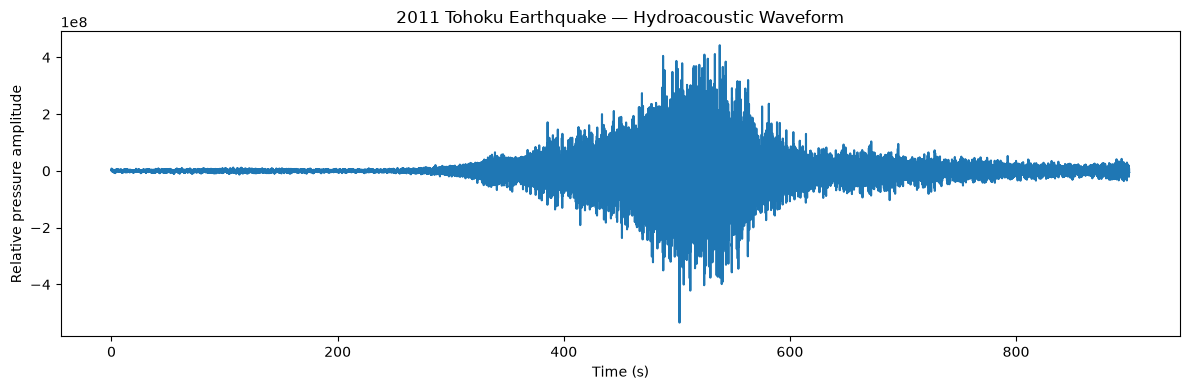

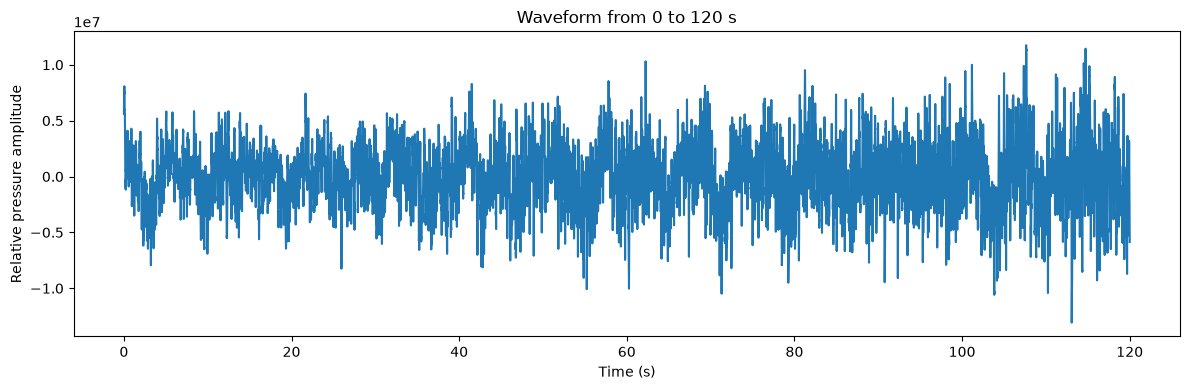

In [2]:
# Plot the complete hydroacoustic record

plt.figure(figsize=(12, 4))

plt.plot(time, signal)

plt.xlabel("Time (s)")
plt.ylabel("Relative pressure amplitude")
plt.title("2011 Tohoku Earthquake — Hydroacoustic Waveform")

plt.tight_layout()
plt.show()


# Zoom into a selected interval
# Change these values after inspecting the full waveform

start_time = 0
end_time = 120

mask = (time >= start_time) & (time <= end_time)

plt.figure(figsize=(12, 4))

plt.plot(time[mask], signal[mask])

plt.xlabel("Time (s)")
plt.ylabel("Relative pressure amplitude")
plt.title(f"Waveform from {start_time} to {end_time} s")

plt.tight_layout()
plt.show()

## 2. Examine the frequency content

The FFT converts the signal from the time domain to the frequency domain.

This allows us to identify which frequencies contribute most strongly to the recorded signal.

Questions:

1. Is most of the energy concentrated at low or high frequencies?
2. Is the signal narrowband or broadband?
3. Are there clear peaks in the spectrum?
4. Which frequency range appears most important?

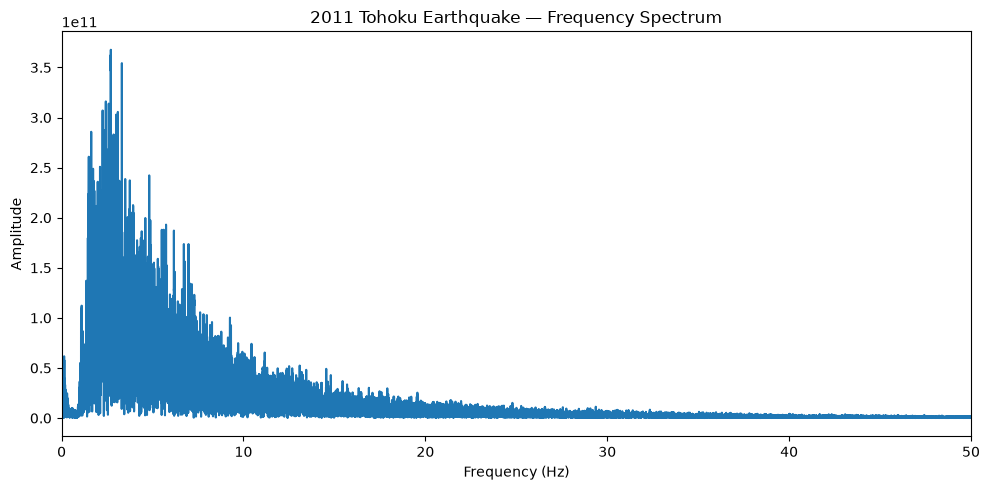

In [3]:
# Calculate the FFT

N = len(signal)

fft_values = np.fft.rfft(signal)

frequencies = np.fft.rfftfreq(
    N,
    d=1/fs
)

amplitude_spectrum = np.abs(fft_values)


# Plot the lower-frequency part of the spectrum

max_frequency = 50

plt.figure(figsize=(10, 5))

plt.plot(
    frequencies,
    amplitude_spectrum
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("2011 Tohoku Earthquake — Frequency Spectrum")

plt.xlim(0, max_frequency)

plt.tight_layout()
plt.show()

## 3. Examine how frequency changes through time

The FFT shows which frequencies are present, but not when they occur.

A spectrogram shows:

- time on the horizontal axis;
- frequency on the vertical axis;
- relative signal intensity through colour.

This makes it possible to examine how the earthquake signal evolves through time.

Questions:

1. When does the strongest acoustic energy occur?
2. Which frequencies dominate the event?
3. Does the frequency content change through time?
4. Is the earthquake easier to identify in the spectrogram than in the waveform?

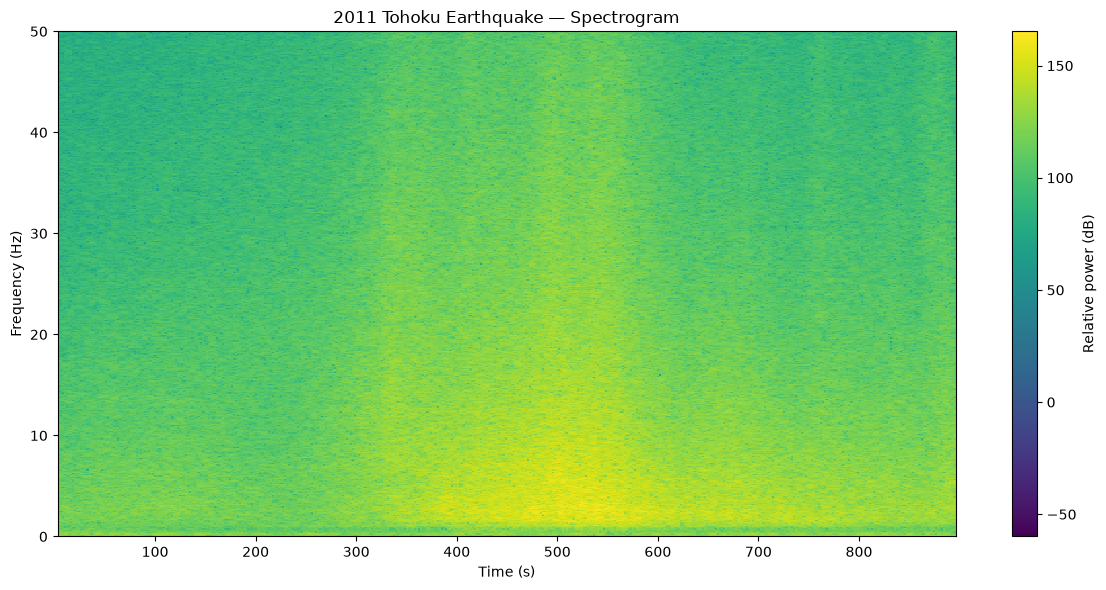

In [4]:
# Calculate the spectrogram

frequencies_s, times_s, Sxx = spectrogram(
    signal,
    fs=fs,
    nperseg=2048,
    noverlap=1536
)

# Convert power to decibels

Sxx_db = 10 * np.log10(Sxx + 1e-12)


# Plot the spectrogram

plt.figure(figsize=(12, 6))

plt.pcolormesh(
    times_s,
    frequencies_s,
    Sxx_db,
    shading="auto"
)

plt.colorbar(label="Relative power (dB)")

plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("2011 Tohoku Earthquake — Spectrogram")

plt.ylim(0, 50)

plt.tight_layout()
plt.show()

## 4. Apply a simple band-pass filter

Filtering can be used to retain a selected range of frequencies and reduce frequencies outside that range.

Here, a band-pass filter is used to retain frequencies between 0.5 and 50 Hz.

Compare the original and filtered signals.

Questions:

1. Which parts of the signal are reduced?
2. Is the earthquake easier to see after filtering?
3. Does the main structure of the event remain?
4. Could filtering also remove useful information?

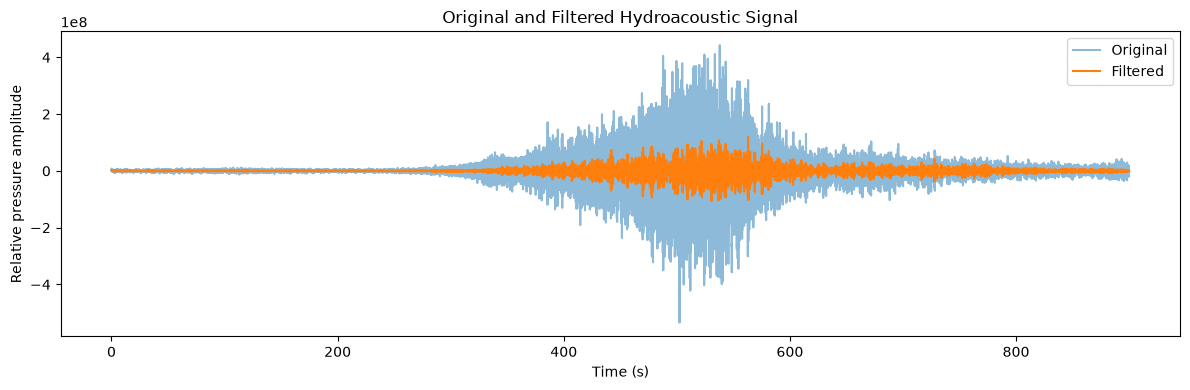

In [9]:
# Define the frequency range to retain

lowcut = 0.5
highcut = 2


# Create a Butterworth band-pass filter

sos = butter(
    4,
    [lowcut, highcut],
    btype="bandpass",
    fs=fs,
    output="sos"
)


# Apply the filter

filtered_signal = sosfiltfilt(
    sos,
    signal
)


# Compare the original and filtered signals

plt.figure(figsize=(12, 4))

plt.plot(
    time,
    signal,
    label="Original",
    alpha=0.5
)

plt.plot(
    time,
    filtered_signal,
    label="Filtered"
)

plt.xlabel("Time (s)")
plt.ylabel("Relative pressure amplitude")
plt.title("Original and Filtered Hydroacoustic Signal")

plt.legend()

plt.tight_layout()
plt.show()

## Final interpretation

Use the waveform, FFT, spectrogram and filtered signal to answer the following:

1. What are the main characteristics of the earthquake signal?
2. Which frequency range contains most of the useful acoustic energy?
3. How does the earthquake differ from the background sound?
4. Which representation was most useful: waveform, FFT or spectrogram?
5. Did filtering improve the interpretation?
6. What uncertainty remains when identifying an earthquake from hydroacoustic data alone?

Remember that the hydrophone records the acoustic signal associated with the earthquake.

It does not directly measure earthquake magnitude, fault slip or tsunami height.